# VAE

### Front matter

---
### exercise: resolucao_vae
### ai_use: "Claude no código; a análise é minha."
---

# Exercício 1
## A - Carregue e divida os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import random_split
from torchvision import datasets, transforms
from scipy.stats import norm

# Regra: fixar as sementes e rodar tudo em CPU (reprodutibilidade)
DEVICE = torch.device("cpu")
torch.manual_seed(42)

# Divisão EXATAMENTE como no enunciado
train_full = datasets.MNIST("data", train=True, download=True, transform=transforms.ToTensor())
test = datasets.MNIST("data", train=False, download=True, transform=transforms.ToTensor())
train, val = random_split(train_full, [50_000, 10_000],
                          generator=torch.Generator().manual_seed(42))

# Para treinar rápido, materializo os splits como tensores (N, 784).
# .data é uint8 em [0, 255]; dividir por 255 é o mesmo que o ToTensor() faz -> pixels em [0, 1]
def para_tensor(dataset_base, indices=None):
    dados = dataset_base.data if indices is None else dataset_base.data[indices]
    rotulos = dataset_base.targets if indices is None else dataset_base.targets[indices]
    return dados.float().div(255.0).view(-1, 784), rotulos

X_train, y_train = para_tensor(train_full, train.indices)
X_val,   y_val   = para_tensor(train_full, val.indices)
X_test,  y_test  = para_tensor(test)   # teste: só usado nos números finais

print(f"Treino: {tuple(X_train.shape)} | Validação: {tuple(X_val.shape)} | Teste: {tuple(X_test.shape)}")
print(f"Intervalo dos pixels: [{X_train.min():.1f}, {X_train.max():.1f}]")

100%|██████████| 9.91M/9.91M [03:18<00:00, 50.0kB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 210kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.53MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.70MB/s]


Treino: (50000, 784) | Validação: (10000, 784) | Teste: (10000, 784)
Intervalo dos pixels: [0.0, 1.0]


## B - Construa o modelo

In [2]:
class VAE(nn.Module):
    """VAE do enunciado: 784 -> 512 -> 256 -> (mu, logvar) -> d -> 256 -> 512 -> 784."""
    def __init__(self, d=16):
        super().__init__()
        self.d = d
        # Encoder: ReLU depois de cada camada
        self.enc = nn.Sequential(
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
        )
        # Duas cabeças lineares 256 -> d
        self.fc_mu = nn.Linear(256, d)
        self.fc_logvar = nn.Linear(256, d)
        # Decoder: ReLU nas ocultas, sigmoide na saída (probabilidade de cada pixel estar "aceso")
        self.dec = nn.Sequential(
            nn.Linear(d, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar, generator=None):
        # Truque da reparametrização (escrito à mão): z = mu + sigma * eps, eps ~ N(0, I)
        # sigma = exp(0.5 * logvar). O ruído eps não depende dos parâmetros -> o gradiente passa por mu e sigma.
        eps = torch.randn(mu.shape, generator=generator, device=mu.device)
        return mu + torch.exp(0.5 * logvar) * eps

    def decode(self, z):
        return self.dec(z)

    def forward(self, x, generator=None):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar, generator)
        return self.decode(z), mu, logvar


def vae_loss(x, x_hat, mu, logvar, beta=1.0):
    """Perda por imagem, em nats: devolve (reconstrução, KL), cada um MÉDIO sobre o lote.

    reconstrução = BCE somada sobre os 784 pixels (verossimilhança de Bernoulli)
    KL           = 1/2 * sum_i (mu_i^2 + sigma_i^2 - 1 - log sigma_i^2), forma fechada de KL(q(z|x) || N(0, I))
    """
    B = x.shape[0]
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / B
    kl = 0.5 * torch.sum(mu.pow(2) + logvar.exp() - 1.0 - logvar) / B
    return recon, kl

# Sanidade: arquitetura e uma passada
torch.manual_seed(42)
_m = VAE(d=16)
print(_m)
_xh, _mu, _lv = _m(X_train[:8])
print("Saídas:", tuple(_xh.shape), tuple(_mu.shape), tuple(_lv.shape))
print("Perda de um lote sem treino (recon, KL):", [round(v.item(), 2) for v in vae_loss(X_train[:8], _xh, _mu, _lv)])

VAE(
  (enc): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=16, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)
Saídas: (8, 784) (8, 16) (8, 16)
Perda de um lote sem treino (recon, KL): [544.81, 0.03]


## C - Treine

In [3]:
@torch.no_grad()
def avaliar(model, X, beta=1.0, bs=1000, seed=123):
    """Reconstrução e KL médios por imagem (nats) em X. z é amostrado (com gerador fixo, p/ reprodutibilidade)."""
    model.eval()
    g = torch.Generator().manual_seed(seed)
    soma_rec, soma_kl = 0.0, 0.0
    for i in range(0, len(X), bs):
        xb = X[i:i+bs]
        x_hat, mu, logvar = model(xb, generator=g)
        rec, kl = vae_loss(xb, x_hat, mu, logvar, beta)
        soma_rec += rec.item() * len(xb)
        soma_kl += kl.item() * len(xb)
    return soma_rec / len(X), soma_kl / len(X)


def treinar(d, epocas=20, lr=1e-3, bs=128, beta=1.0):
    """Treina um VAE com latente de dimensão d e devolve (modelo, histórico). Decisões só olham a validação."""
    torch.manual_seed(42)                       # semente antes de construir o modelo
    model = VAE(d=d).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g_dados = torch.Generator().manual_seed(42)  # embaralhamento reprodutível
    g_ruido = torch.Generator().manual_seed(42)  # ruído da reparametrização reprodutível
    hist = {"train_rec": [], "train_kl": [], "val_rec": [], "val_kl": []}

    for ep in range(1, epocas + 1):
        model.train()
        perm = torch.randperm(len(X_train), generator=g_dados)
        soma_rec, soma_kl = 0.0, 0.0
        for i in range(0, len(X_train), bs):
            xb = X_train[perm[i:i+bs]]
            x_hat, mu, logvar = model(xb, generator=g_ruido)
            rec, kl = vae_loss(xb, x_hat, mu, logvar, beta)
            loss = rec + beta * kl
            opt.zero_grad()
            loss.backward()
            opt.step()
            soma_rec += rec.item() * len(xb)    # média ao longo da época (ponderada pelo tamanho do lote)
            soma_kl += kl.item() * len(xb)
        v_rec, v_kl = avaliar(model, X_val, beta)
        hist["train_rec"].append(soma_rec / len(X_train))
        hist["train_kl"].append(soma_kl / len(X_train))
        hist["val_rec"].append(v_rec)
        hist["val_kl"].append(v_kl)
        print(f"[d={d}] época {ep:2d} | treino: rec={hist['train_rec'][-1]:7.2f} KL={hist['train_kl'][-1]:6.2f} "
              f"| val: rec={v_rec:7.2f} KL={v_kl:6.2f}")
    return model, hist

In [4]:
# Exercício 1: VAE com d = 16
vae16, hist16 = treinar(d=16)

# Números FINAIS no teste (único uso do conjunto de teste)
rec16, kl16 = avaliar(vae16, X_test)
print("\n--- Teste (d=16), nats por imagem ---")
print(f"Reconstrução: {rec16:.2f}")
print(f"KL:           {kl16:.2f}")
print(f"ELBO negativo (rec + KL): {rec16 + kl16:.2f}")

[d=16] época  1 | treino: rec= 173.28 KL=  7.35 | val: rec= 127.42 KL= 12.88
[d=16] época  2 | treino: rec= 115.35 KL= 14.44 | val: rec= 107.86 KL= 15.38
[d=16] época  3 | treino: rec= 103.71 KL= 15.77 | val: rec= 101.48 KL= 15.65
[d=16] época  4 | treino: rec=  98.30 KL= 16.57 | val: rec=  96.73 KL= 16.96
[d=16] época  5 | treino: rec=  94.56 KL= 17.27 | val: rec=  93.97 KL= 17.29
[d=16] época  6 | treino: rec=  92.09 KL= 17.65 | val: rec=  91.67 KL= 17.84
[d=16] época  7 | treino: rec=  90.09 KL= 18.01 | val: rec=  90.07 KL= 17.89
[d=16] época  8 | treino: rec=  88.44 KL= 18.37 | val: rec=  89.11 KL= 18.11
[d=16] época  9 | treino: rec=  87.10 KL= 18.61 | val: rec=  87.65 KL= 18.44
[d=16] época 10 | treino: rec=  86.01 KL= 18.83 | val: rec=  86.22 KL= 19.17
[d=16] época 11 | treino: rec=  85.19 KL= 18.96 | val: rec=  86.57 KL= 18.48
[d=16] época 12 | treino: rec=  84.47 KL= 19.05 | val: rec=  85.32 KL= 19.06
[d=16] época 13 | treino: rec=  83.87 KL= 19.11 | val: rec=  85.30 KL= 18.75

**Números no teste (d = 16), em nats por imagem** *(preencha com a saída acima)*:

- Reconstrução: 81.72
- KL: 19.66
- ELBO negativo (soma): 101.38

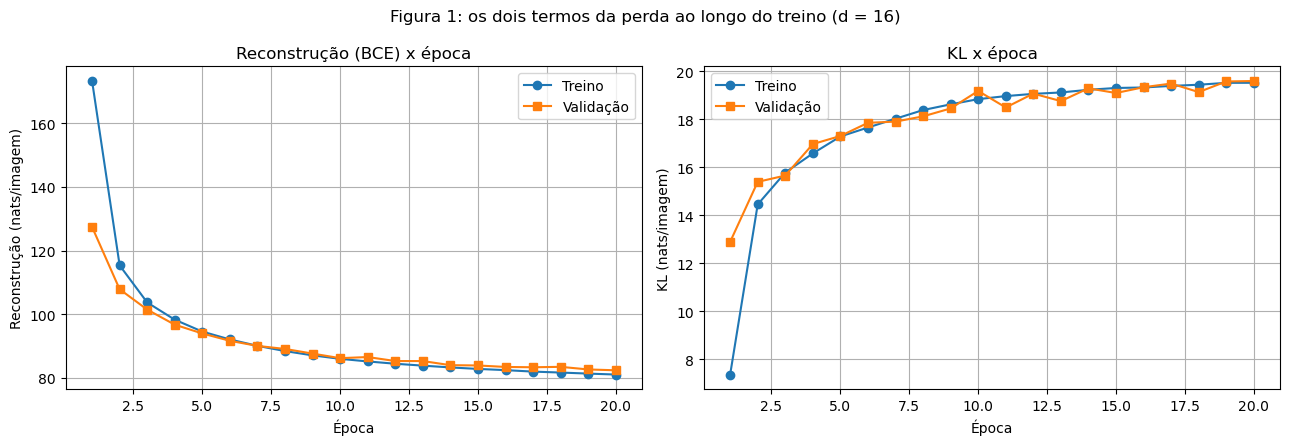

KL de validação - primeira época: 12.88 | última época: 19.58


In [13]:
# Figura 1: reconstrução x época e KL x época (treino e validação)
epocas_x = np.arange(1, len(hist16["train_rec"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epocas_x, hist16["train_rec"], marker="o", label="Treino")
axes[0].plot(epocas_x, hist16["val_rec"], marker="s", label="Validação")
axes[0].set_title("Reconstrução (BCE) x época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Reconstrução (nats/imagem)")
axes[0].legend(); axes[0].grid(True)

axes[1].plot(epocas_x, hist16["train_kl"], marker="o", label="Treino")
axes[1].plot(epocas_x, hist16["val_kl"], marker="s", label="Validação")
axes[1].set_title("KL x época")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("KL (nats/imagem)")
axes[1].legend(); axes[1].grid(True)

plt.suptitle("Figura 1: os dois termos da perda ao longo do treino (d = 16)")
plt.tight_layout()
plt.show()

print(f"KL de validação - primeira época: {hist16['val_kl'][0]:.2f} | última época: {hist16['val_kl'][-1]:.2f}")

## D - Reconstruções e amostras

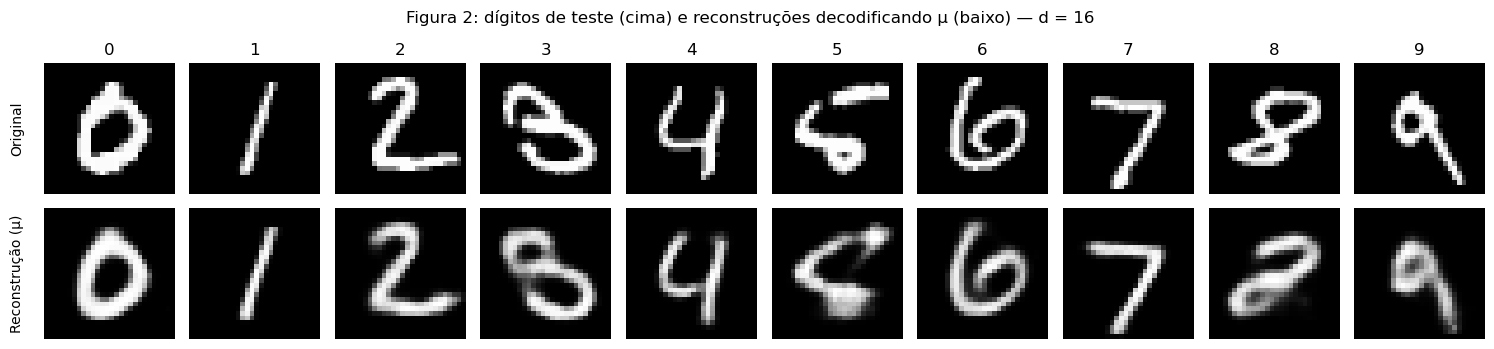

Índices de teste usados na Figura 2: [3, 2, 1, 18, 4, 8, 11, 0, 61, 7]


In [6]:
# Helper: organiza n imagens (N, 784) em uma grade nrow x ncol (preenchida linha a linha)
def montar_grade(imgs, nrow, ncol):
    imgs = np.asarray(imgs).reshape(nrow, ncol, 28, 28)
    return imgs.transpose(0, 2, 1, 3).reshape(nrow * 28, ncol * 28)

# Figura 2: primeira imagem de teste de cada dígito (linha de cima) e sua reconstrução (linha de baixo)
idx_primeiro = [int((y_test == k).nonzero()[0]) for k in range(10)]
vae16.eval()
with torch.no_grad():
    originais = X_test[idx_primeiro]
    mu_, _ = vae16.encode(originais)
    recons = vae16.decode(mu_)          # decodifica mu (NÃO amostra z)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for k in range(10):
    axes[0, k].imshow(originais[k].view(28, 28), cmap="gray")
    axes[1, k].imshow(recons[k].view(28, 28), cmap="gray")
    axes[0, k].set_title(f"{k}")
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].text(-0.15, 0.5, "Original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.15, 0.5, "Reconstrução (μ)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Figura 2: dígitos de teste (cima) e reconstruções decodificando μ (baixo) — d = 16")
plt.tight_layout()
plt.show()
print("Índices de teste usados na Figura 2:", idx_primeiro)

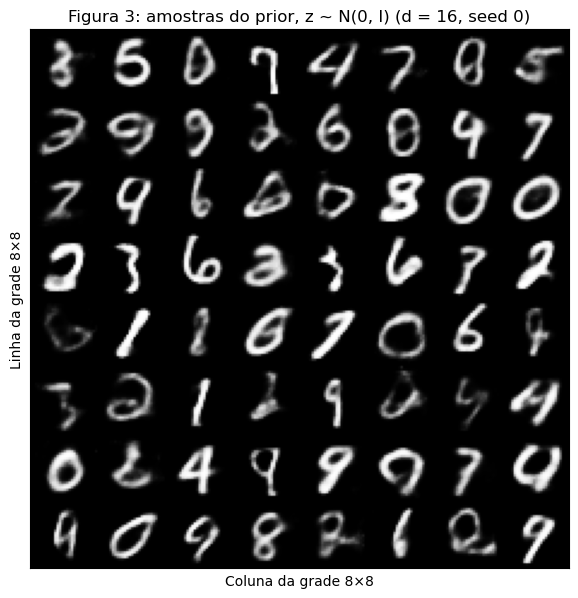

In [7]:
# Figura 3: grade 8x8 de imagens decodificadas de z ~ N(0, I)
torch.manual_seed(0)
z_prior = torch.randn(64, 16)
with torch.no_grad():
    amostras = vae16.decode(z_prior)

plt.figure(figsize=(7, 7))
plt.imshow(montar_grade(amostras.numpy(), 8, 8), cmap="gray")
plt.title("Figura 3: amostras do prior, z ~ N(0, I) (d = 16, seed 0)")
plt.xlabel("Coluna da grade 8×8")
plt.ylabel("Linha da grade 8×8")
plt.xticks([]); plt.yticks([])
plt.show()

## E - Análise

1. **Por que a KL sobe nas primeiras épocas enquanto a perda total cai**: Isso acontece porque, no começo, a rede ainda está aprendendo a representar os dígitos no espaço latente. Conforme ela aprende, começa a guardar mais informações sobre cada imagem, fazendo a KL aumentar. Na validação, ela saiu de 12.88 para 19.58. Contudo, o erro de reconstrução diminui muito mais do que a KL aumenta, ou seja, o modelo passa a reconstruir melhor os dígitos, compensando esse aumento e diminuindo a perda total.

2. **Por que a Figura 3 parece pior que a Figura 2**: Na Figura 2, o modelo reconstrói imagens reais, utilizando pontos do espaço latente que já foram encontrados pelo encoder. Já na Figura 3, os pontos são sorteados aleatoriamente de uma distribuição normal, podendo cair em regiões que o decoder não aprendeu tão bem. Além disso, o decoder produz uma imagem com probabilidades para cada pixel, o que pode acabar misturando características de vários dígitos, deixando algumas imagens mais borradas ou difíceis de identificar.

3. **Por que decodificar mi e não um z amostrado na Figura 2**: Porque o mi representa o ponto central da distribuição que o encoder encontrou para cada imagem. Se utilizássemos um z amostrado, estaríamos adicionando um ruído aleatório, que poderia mudar o formato dos dígitos a cada execução. Desta forma, usando o mi, conseguimos reconstruções mais estáveis e comparar melhor a imagem original com o resultado da rede.

# Exercício 2
## A - Treine um VAE 2-D

In [8]:
# Mesmo modelo, dados, semente, beta e orçamento de treino; muda só d = 2
vae2, hist2 = treinar(d=2)

rec2, kl2 = avaliar(vae2, X_test)

comparacao = pd.DataFrame({
    "Reconstrução (nats)": [rec16, rec2],
    "KL (nats)": [kl16, kl2],
    "ELBO negativo (nats)": [rec16 + kl16, rec2 + kl2],
}, index=["d = 16", "d = 2"]).round(2)
print("--- Teste, nats por imagem ---")
display(comparacao)

[d=2] época  1 | treino: rec= 183.74 KL=  3.69 | val: rec= 160.15 KL=  4.87
[d=2] época  2 | treino: rec= 155.43 KL=  5.38 | val: rec= 152.23 KL=  5.42
[d=2] época  3 | treino: rec= 149.39 KL=  5.72 | val: rec= 147.45 KL=  5.85
[d=2] época  4 | treino: rec= 145.94 KL=  5.92 | val: rec= 145.30 KL=  5.97
[d=2] época  5 | treino: rec= 143.61 KL=  6.05 | val: rec= 143.34 KL=  6.14
[d=2] época  6 | treino: rec= 141.76 KL=  6.15 | val: rec= 142.28 KL=  5.94
[d=2] época  7 | treino: rec= 140.27 KL=  6.21 | val: rec= 140.33 KL=  6.26
[d=2] época  8 | treino: rec= 138.98 KL=  6.31 | val: rec= 139.22 KL=  6.29
[d=2] época  9 | treino: rec= 138.09 KL=  6.35 | val: rec= 138.09 KL=  6.54
[d=2] época 10 | treino: rec= 137.32 KL=  6.40 | val: rec= 138.39 KL=  6.32
[d=2] época 11 | treino: rec= 136.58 KL=  6.45 | val: rec= 137.69 KL=  6.56
[d=2] época 12 | treino: rec= 135.82 KL=  6.47 | val: rec= 136.90 KL=  6.45
[d=2] época 13 | treino: rec= 135.32 KL=  6.53 | val: rec= 136.87 KL=  6.53
[d=2] época 

,Reconstrução (nats),KL (nats),ELBO negativo (nats)
d = 16,81.72,19.66,101.38
d = 2,134.63,6.68,141.31


**Números no teste, em nats por imagem**:

| Modelo | Reconstrução | KL |
|---|---|---|
| d = 16 | 81.72 | 19.66 |
| d = 2 | 134.63 | 6.68 |

## B - O conjunto de teste codificado

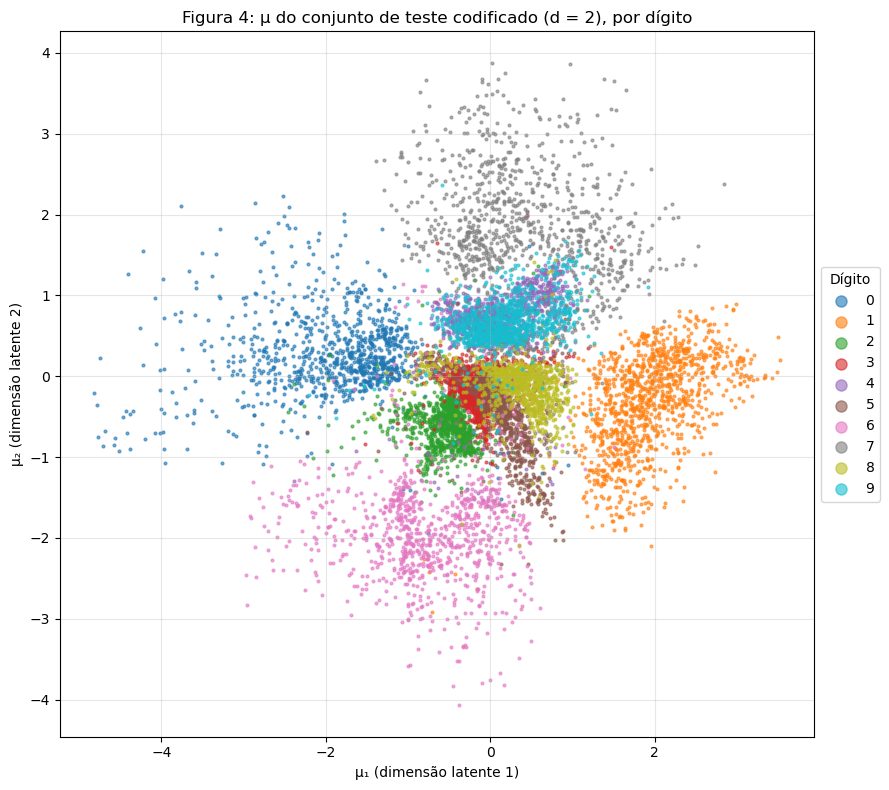

In [9]:
# Figura 4: dispersão de mu (2-D) para as 10 000 imagens de teste, colorido por dígito
vae2.eval()
with torch.no_grad():
    mu_teste, _ = vae2.encode(X_test)
mu_teste = mu_teste.numpy()

plt.figure(figsize=(9, 8))
cores = plt.get_cmap("tab10")
for k in range(10):
    sel = (y_test == k).numpy()
    plt.scatter(mu_teste[sel, 0], mu_teste[sel, 1], s=4, alpha=0.6, color=cores(k), label=str(k))
plt.title("Figura 4: μ do conjunto de teste codificado (d = 2), por dígito")
plt.xlabel("μ₁ (dimensão latente 1)")
plt.ylabel("μ₂ (dimensão latente 2)")
plt.legend(title="Dígito", markerscale=4, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## C - O plano decodificado

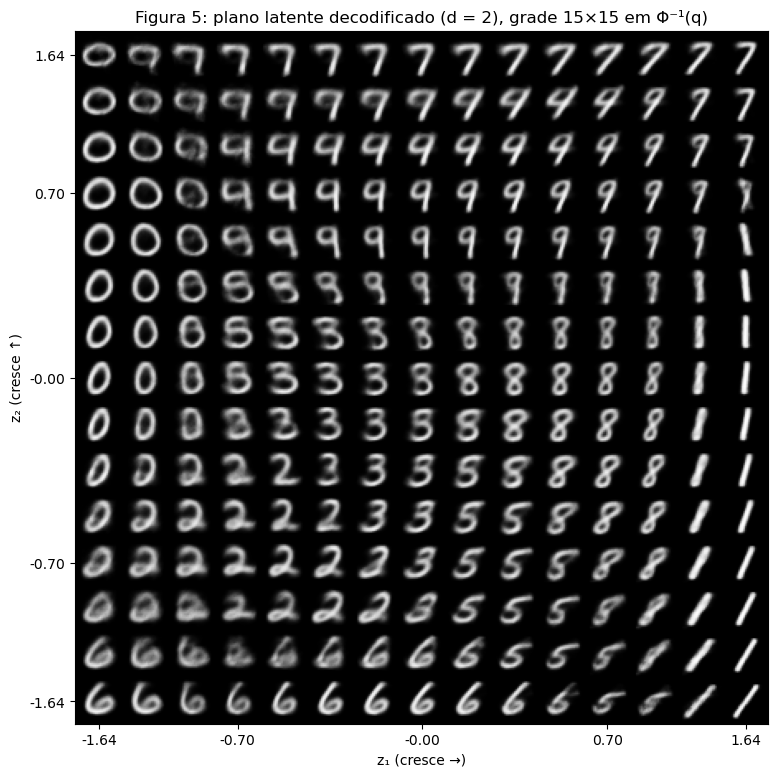

In [10]:
# Figura 5: grade 15x15 no plano latente, espaçada pelos quantis da N(0, 1): z = Phi^{-1}(q)
n = 15
q = np.linspace(0.05, 0.95, n)
z_eixo = norm.ppf(q)                       # 15 valores; cada célula tem a mesma massa do prior

# Linhas: z2 decrescente (topo = z2 maior, como em um gráfico); colunas: z1 crescente
z_grade = np.array([[z1, z2] for z2 in z_eixo[::-1] for z1 in z_eixo], dtype=np.float32)

vae2.eval()
with torch.no_grad():
    imgs_plano = vae2.decode(torch.from_numpy(z_grade)).numpy()

plt.figure(figsize=(9, 9))
plt.imshow(montar_grade(imgs_plano, n, n), cmap="gray")
plt.title("Figura 5: plano latente decodificado (d = 2), grade 15×15 em Φ⁻¹(q)")
plt.xlabel("z₁ (cresce →)")
plt.ylabel("z₂ (cresce ↑)")
# marca alguns valores de z nos eixos para orientar a leitura
ticks = [0, 3, 7, 11, 14]
plt.xticks([t * 28 + 14 for t in ticks], [f"{z_eixo[t]:.2f}" for t in ticks])
plt.yticks([t * 28 + 14 for t in ticks], [f"{z_eixo[::-1][t]:.2f}" for t in ticks])
plt.show()

**Por que esse espaçamento dá a cada célula a mesma massa do prior?**
Porque o espaçamento foi calculado pelos quantis da distribuição normal, fazendo com que cada célula tenha a mesma probabilidade de receber uma amostra do prior, mesmo que as distâncias entre os pontos sejam diferentes.

## D - Interpolação

Índices de teste interpolados: a = 18 (dígito 3), b = 61 (dígito 8)


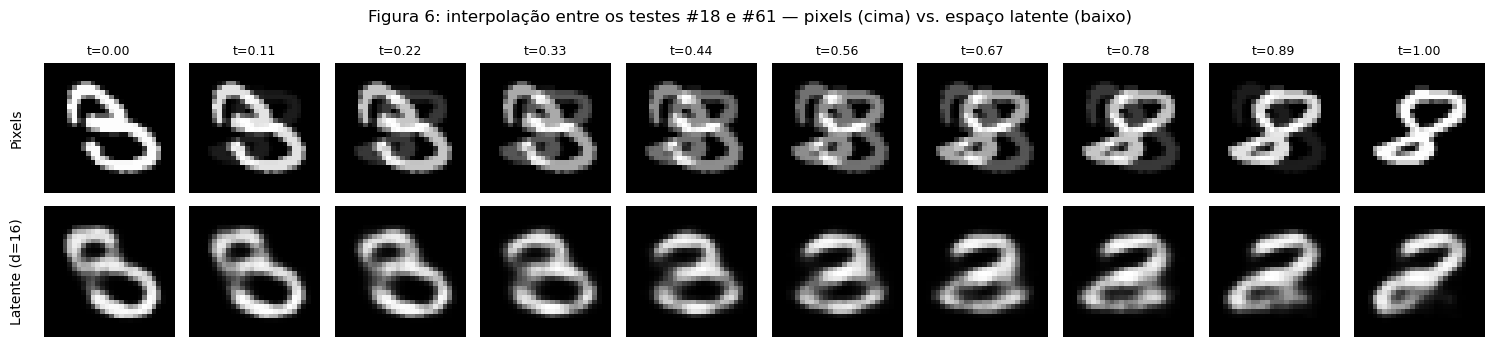

In [11]:
# Escolha de duas imagens de teste de dígitos DIFERENTES (edite os dígitos se quiser outros)
DIGITO_A, DIGITO_B = 3, 8
idx_a = int((y_test == DIGITO_A).nonzero()[0])   # primeira ocorrência do dígito A no teste
idx_b = int((y_test == DIGITO_B).nonzero()[0])   # primeira ocorrência do dígito B no teste
assert y_test[idx_a] != y_test[idx_b], "Escolha dígitos diferentes"
print(f"Índices de teste interpolados: a = {idx_a} (dígito {y_test[idx_a].item()}), b = {idx_b} (dígito {y_test[idx_b].item()})")

xa, xb = X_test[idx_a], X_test[idx_b]
ts = np.linspace(0, 1, 10)

# Linha de cima: interpolação no ESPAÇO DOS PIXELS -> (1 - t) x_a + t x_b
linha_pixels = np.stack([((1 - t) * xa + t * xb).numpy() for t in ts])

# Linha de baixo: interpolação no ESPAÇO LATENTE (modelo d = 16) -> decode((1 - t) mu_a + t mu_b)
vae16.eval()
with torch.no_grad():
    mu_a, _ = vae16.encode(xa.unsqueeze(0))
    mu_b, _ = vae16.encode(xb.unsqueeze(0))
    linha_latente = np.stack([vae16.decode((1 - t) * mu_a + t * mu_b).squeeze(0).numpy() for t in ts])

fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for j, t in enumerate(ts):
    axes[0, j].imshow(linha_pixels[j].reshape(28, 28), cmap="gray")
    axes[1, j].imshow(linha_latente[j].reshape(28, 28), cmap="gray")
    axes[0, j].set_title(f"t={t:.2f}", fontsize=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].text(-0.15, 0.5, "Pixels", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.15, 0.5, "Latente (d=16)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle(f"Figura 6: interpolação entre os testes #{idx_a} e #{idx_b} — pixels (cima) vs. espaço latente (baixo)")
plt.tight_layout()
plt.show()

## E - Análise

1. **Quais dígitos se sobrepõem na Figura 4**: Na Figura 4, podemos perceber que vários dígitos se misturam, principalmente o 3, 5 e 8, que ficam muito próximos no centro do gráfico. Já na Figura 5, conseguimos observar essa transição, onde o 3 vai perdendo seu formato e ganhando características do 8. No meio do caminho, as imagens acabam ficando com traços misturados e um pouco borrados, dificultando identificar exatamente qual dígito está sendo representado.

2. **Por que d=2 reconstrói pior que d=16**: Com apenas dois números para representar cada imagem, a rede precisa descartar muitas informações, como a espessura dos traços, a inclinação e os pequenos detalhes que diferenciam os dígitos. Na Figura 5, podemos perceber que várias imagens ficam parecidas e algumas acabam misturando características de números diferentes. Isso explica por que o erro de reconstrução com d=2 foi de 134.63, enquanto com d=16 foi de 81.72. Ou seja, com mais dimensões, a rede consegue guardar mais informações e reconstruir melhor os dígitos.

3. **Comparação das duas linhas da Figura 6**: A linha de baixo, que utiliza o espaço latente, consegue passar por imagens que parecem dígitos, pois a rede aprendeu a representar seus formatos e consegue fazer uma transição mais natural. Já a linha de cima mistura diretamente os pixels do 3 e do 8, fazendo com que os dois números apareçam sobrepostos no meio do caminho. Desta forma, a interpolação pelos pixels acaba criando imagens confusas, enquanto a interpolação latente consegue transformar gradualmente o formato de um dígito no outro, mesmo que algumas imagens ainda fiquem borradas.

# Resumo dos resultados

In [12]:
resumo = [
    {"#": 1, "Quantidade": "Ex. 1 — reconstrução, KL e ELBO negativo no teste (d = 16)",
     "Valor": f"rec = {rec16:.2f}, KL = {kl16:.2f}, ELBO neg. = {rec16 + kl16:.2f} nats"},
    {"#": 2, "Quantidade": "Ex. 1 — KL de validação na primeira e na última época",
     "Valor": f"época 1: {hist16['val_kl'][0]:.2f} nats | época {len(hist16['val_kl'])}: {hist16['val_kl'][-1]:.2f} nats"},
    {"#": 3, "Quantidade": "Ex. 2 — reconstrução e KL no teste (d = 2)",
     "Valor": f"rec = {rec2:.2f}, KL = {kl2:.2f} nats"},
    {"#": 4, "Quantidade": "Ex. 2 — os dois índices de teste interpolados",
     "Valor": f"{idx_a} (dígito {y_test[idx_a].item()}) e {idx_b} (dígito {y_test[idx_b].item()})"},
]
df_resumo = pd.DataFrame(resumo).set_index("#")
display(df_resumo)

,Quantidade,Valor
#,,
1,"Ex. 1 — reconstrução, KL e ELBO negativo no te...","rec = 81.72, KL = 19.66, ELBO neg. = 101.38 nats"
2,Ex. 1 — KL de validação na primeira e na últim...,época 1: 12.88 nats | época 20: 19.58 nats
3,Ex. 2 — reconstrução e KL no teste (d = 2),"rec = 134.63, KL = 6.68 nats"
4,Ex. 2 — os dois índices de teste interpolados,18 (dígito 3) e 61 (dígito 8)
